# 02 · Position effects: naive versus randomized

How much does a hotel's position cause clicks and bookings? Under Expedia's ranking, better
hotels are placed higher, so the drop in clicks down the page mixes the effect of the slot
with the quality of what is in it. In the randomly ordered searches, position is (nearly)
unrelated to the hotel, so the drop there is the effect of the slot.

Sample: the analysis sample from notebook 01 (searches with valid prices, not sorted by
price), reserved slots 5, 11, 17 and 23 excluded. Intervals: search-level bootstrap for the
raw curves, search-clustered standard errors for the regressions.

In [1]:
import sys
from pathlib import Path

def _project_root() -> Path:
    """The folder holding src/hotelrank, wherever the script or notebook was started."""
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "hotelrank" / "__init__.py").exists():
            return p
    for marker in here.glob("*/src/hotelrank/__init__.py"):
        return marker.parents[2]
    raise FileNotFoundError("run from inside the project folder")


sys.path.insert(0, str(_project_root() / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from hotelrank import audit, position
from hotelrank.data import FIGURES_DIR, ROOT as PROJECT_ROOT, load
from hotelrank.records import write_metrics

N_BOOT = int(__import__("os").environ.get("HOTELRANK_N_BOOT", 200))
COLUMNS = ["srch_id", "position", "random_bool", "click_bool", "booking_bool", "price_usd", "prop_starrating",
           "prop_review_score", "prop_brand_bool", "prop_location_score1", "promotion_flag"]
df, SOURCE = load(COLUMNS)
flags_path = PROJECT_ROOT / "data" / "interim" / "search_flags.parquet"
if SOURCE == "real" and flags_path.exists():
    flags = pd.read_parquet(flags_path)
else:  # synthetic run, or notebook 01 not yet run
    flags = audit.price_flags(df, audit.per_search(df)).reset_index().rename(columns={"index": "srch_id"})
x = position.analysis_sample(df, flags)
del df
arms = {"algorithm": x[~x["random_bool"].astype(bool)], "random": x[x["random_bool"].astype(bool)]}
print(SOURCE, {k: (len(v), v["srch_id"].nunique()) for k, v in arms.items()})

real {'algorithm': (6648606, 267352), 'random': (2767426, 114681)}


## 1. Why the comparison uses a balanced panel

Positions near the bottom exist only in long result lists, and in a long list each hotel's
share of the (at least one) click is smaller. Pooling all searches therefore compares
position 1 in every search with position 30 in long searches only, and overstates the drop.
The headline uses a **balanced panel**: searches that show a hotel in every slot from 1 to
30, so every position is measured on the same searches.

In [2]:
panel = {arm: position.balanced_panel(d, 30) for arm, d in arms.items()}
pooled = position.rate_by_position(arms["random"], "click_bool", n_boot=1, seed=1, max_position=30)
composition = {
    "random_click_pos1_over_pos30_pooled": round(float(1 / pooled.set_index("position").loc[30, "rel_to_1"]), 3),
    "panel_searches": {arm: int(d["srch_id"].nunique()) for arm, d in panel.items()},
    "panel_share_of_searches": {arm: round(panel[arm]["srch_id"].nunique() / arms[arm]["srch_id"].nunique(), 4)
                                for arm in arms},
}
# Random-arm searches with at least 30 results, for the comparison with the published estimate (section 4).
long = arms["random"][arms["random"].groupby("srch_id")["position"].transform("size") >= 30]
sample = {arm: {"impressions": int(len(d)), "searches": int(d["srch_id"].nunique())} for arm, d in arms.items()}
del arms, x  # keep memory low: everything below uses the panel or `long`

## 2. Raw curves on the balanced panel

Click and booking rate at each position, relative to position 1, with search-level bootstrap
intervals. Booking rates are only compared within an arm (notebook 01); relative curves
compare shapes, which is what the position effect is.

In [3]:
curves = {(arm, out): position.rate_by_position(d, out, n_boot=N_BOOT, seed=7, max_position=30)
          for arm, d in panel.items() for out in ("click_bool", "booking_bool")}
ratios = {f"{arm}/{out}": position.ratio_summary(c) for (arm, out), c in curves.items()}
composition["random_click_pos1_over_pos30_panel"] = ratios["random/click_bool"]["pos1_over_pos30"]["ratio"]
bias = {out: {k: round(ratios[f"algorithm/{out}"][k]["ratio"] / ratios[f"random/{out}"][k]["ratio"], 2)
              for k in ratios[f"random/{out}"]} for out in ("click_bool", "booking_bool")}
print(composition)
pd.DataFrame({k: {kk: vv["ratio"] for kk, vv in v.items()} for k, v in ratios.items()})

{'random_click_pos1_over_pos30_pooled': 6.184, 'panel_searches': {'algorithm': 153491, 'random': 65122}, 'panel_share_of_searches': {'algorithm': 0.5741, 'random': 0.5679}, 'random_click_pos1_over_pos30_panel': 4.915}


,algorithm/click_bool,algorithm/booking_bool,random/click_bool,random/booking_bool
pos1_over_pos10,4.514,4.915,2.775,3.226
pos1_over_pos20,9.218,10.430,3.716,5.278
pos1_over_pos30,16.782,19.577,4.915,7.917


## 3. Adjusting for the random arm's residual tilt

Notebook 01 found that higher-star hotels still sit slightly higher in the random arm. A
within-search linear probability model (search fixed effects, position dummies) with hotel
attributes as controls removes that tilt. If the adjusted curve is close to the raw one, the
tilt does not drive the result. The same model on the algorithm arm asks whether observed
attributes alone can rescue the naive estimate.

In [4]:
fits = {}
for out in ("click_bool", "booking_bool"):
    for arm in ("random", "algorithm"):
        fits[(arm, out, "raw")] = position.within_search_lpm(panel[arm], out, None, max_position=30)
        fits[(arm, out, "adjusted")] = position.within_search_lpm(panel[arm], out, position.CONTROLS, max_position=30)
lpm_curves = {k: position.lpm_curve(f) for k, f in fits.items()}


def rel_at(curve, k):
    return float(curve.set_index("position").loc[k, "rel_to_1"])


adjusted_ratios = {"/".join(key): {f"pos1_over_pos{k}": round(1 / rel_at(c, k), 3) for k in (10, 20, 30)}
                   for key, c in lpm_curves.items()}
controls = {out: {nm: {"beta": round(float(b), 5), "se": round(float(s), 5)}
                  for nm, b, s in zip(fits[("random", out, "adjusted")]["names"],
                                      fits[("random", out, "adjusted")]["beta"],
                                      fits[("random", out, "adjusted")]["se"]) if not nm.startswith("pos_")}
            for out in ("click_bool", "booking_bool")}
pd.DataFrame(adjusted_ratios)

,random/click_bool/raw,random/click_bool/adjusted,algorithm/click_bool/raw,algorithm/click_bool/adjusted,random/booking_bool/raw,random/booking_bool/adjusted,algorithm/booking_bool/raw,algorithm/booking_bool/adjusted
pos1_over_pos10,2.775,2.727,4.514,4.277,3.226,3.159,4.915,4.629
pos1_over_pos20,3.716,3.590,9.218,7.938,5.278,5.017,10.430,8.790
pos1_over_pos30,4.915,4.388,16.782,11.061,7.917,6.543,19.577,12.161


## 3. Comparison with the published estimate

Compiani, Lewis, Peng and Wang (arXiv 2210.16408) estimate, on the same randomized sessions,
an average position effect of 0.14 percentage points per position on clicks (average click
rate 4.39%) and 0.008 points on bookings (average 0.27%), using sessions with at least 30
listings. The comparable number here is the slope of a linear position term, with controls,
on random-arm searches with at least 30 results.

In [5]:
benchmark = {}
for out, (paper_slope, paper_mean) in {"click_bool": (0.14, 4.39), "booking_bool": (0.008, 0.27)}.items():
    f = position.within_search_lpm(long, out, position.CONTROLS, position="linear")
    slope, se = -100 * float(f["beta"][0]), 100 * float(f["se"][0])
    benchmark[out] = {
        "ours_pp_per_position": round(slope, 4), "ours_se": round(se, 4),
        "ours_mean_pct": round(100 * f["mean_outcome"], 3), "ours_searches": f["searches"],
        "paper_pp_per_position": paper_slope, "paper_mean_pct": paper_mean,
        "ours_relative_to_mean": round(slope / (100 * f["mean_outcome"]), 4),
        "paper_relative_to_mean": round(paper_slope / paper_mean, 4),
    }
pd.DataFrame(benchmark)

,click_bool,booking_bool
ours_pp_per_position,0.1443,0.0206
ours_se,0.0015,0.0005
ours_mean_pct,3.5210,0.3800
ours_searches,52349.0000,52349.0000
paper_pp_per_position,0.1400,0.0080
paper_mean_pct,4.3900,0.2700
ours_relative_to_mean,0.0410,0.0541
paper_relative_to_mean,0.0319,0.0296


## 4. Figure

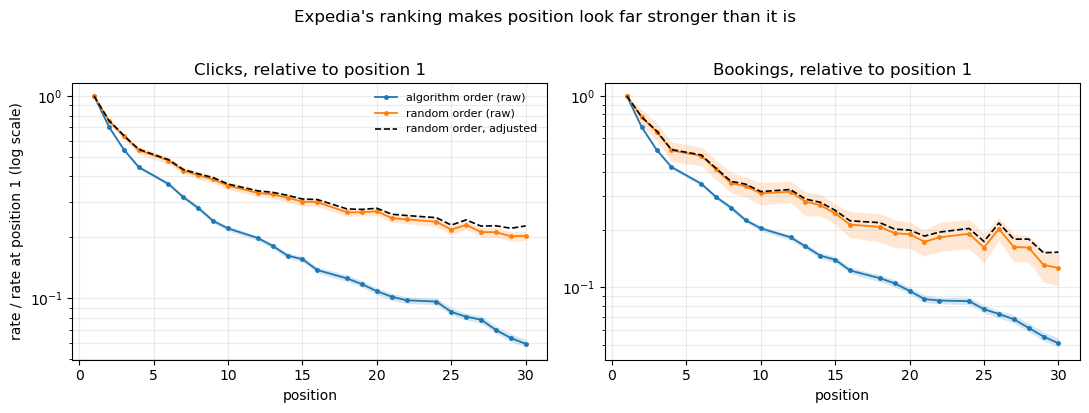

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
colours = {"algorithm": "#1f77b4", "random": "#ff7f0e"}
for ax, out, title in zip(axes, ("click_bool", "booking_bool"), ("Clicks", "Bookings")):
    for arm in ("algorithm", "random"):
        c = curves[(arm, out)]
        ax.plot(c["position"], c["rel_to_1"], marker="o", ms=2.5, lw=1.3, color=colours[arm],
                label=f"{arm} order (raw)")
        ax.fill_between(c["position"], c["rel_lo"], c["rel_hi"], color=colours[arm], alpha=0.18, lw=0)
    adj = lpm_curves[("random", out, "adjusted")]
    ax.plot(adj["position"], adj["rel_to_1"], ls="--", lw=1.2, color="black", label="random order, adjusted")
    ax.set_yscale("log")
    ax.set(xlabel="position", title=f"{title}, relative to position 1")
    ax.grid(alpha=0.25, which="both")
axes[0].set_ylabel("rate / rate at position 1 (log scale)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Expedia's ranking makes position look far stronger than it is", y=1.02)
fig.tight_layout()

In [7]:
def curve_record(c, cols):
    return {int(r.position): {k: round(float(getattr(r, k)), 6) for k in cols} for r in c.itertuples()}


record = {
    "sample": sample,
    "n_boot": N_BOOT,
    "composition": composition,
    "raw_ratios": ratios,
    "naive_over_random_ratio": bias,
    "adjusted_ratios": adjusted_ratios,
    "controls_random_arm": controls,
    "benchmark_compiani_2022": benchmark,
    "raw_curves": {f"{arm}/{out}": curve_record(c, ["impressions", "rate", "lo", "hi", "rel_to_1", "rel_lo", "rel_hi"])
                   for (arm, out), c in curves.items()},
    "lpm_curves": {"/".join(k): curve_record(c, ["diff", "se", "rel_to_1"]) for k, c in lpm_curves.items()},
}
print({k: v for k, v in record.items() if k in ("composition", "naive_over_random_ratio", "adjusted_ratios")})
out_path = write_metrics("02_position_effects", record, SOURCE)
print("wrote", out_path.relative_to(PROJECT_ROOT) if SOURCE == "real" else out_path.name)
if SOURCE == "real":
    fig.savefig(FIGURES_DIR / "02_position_effects.png", dpi=150, bbox_inches="tight")

{'composition': {'random_click_pos1_over_pos30_pooled': 6.184, 'panel_searches': {'algorithm': 153491, 'random': 65122}, 'panel_share_of_searches': {'algorithm': 0.5741, 'random': 0.5679}, 'random_click_pos1_over_pos30_panel': 4.915}, 'naive_over_random_ratio': {'click_bool': {'pos1_over_pos10': 1.63, 'pos1_over_pos20': 2.48, 'pos1_over_pos30': 3.41}, 'booking_bool': {'pos1_over_pos10': 1.52, 'pos1_over_pos20': 1.98, 'pos1_over_pos30': 2.47}}, 'adjusted_ratios': {'random/click_bool/raw': {'pos1_over_pos10': 2.775, 'pos1_over_pos20': 3.716, 'pos1_over_pos30': 4.915}, 'random/click_bool/adjusted': {'pos1_over_pos10': 2.727, 'pos1_over_pos20': 3.59, 'pos1_over_pos30': 4.388}, 'algorithm/click_bool/raw': {'pos1_over_pos10': 4.514, 'pos1_over_pos20': 9.218, 'pos1_over_pos30': 16.782}, 'algorithm/click_bool/adjusted': {'pos1_over_pos10': 4.277, 'pos1_over_pos20': 7.938, 'pos1_over_pos30': 11.061}, 'random/booking_bool/raw': {'pos1_over_pos10': 3.226, 'pos1_over_pos20': 5.278, 'pos1_over_pos3